# Phase I · 03 · How does the fine-tuned ResNet18 behave?

Here we compare ResNet18 with the CNN on the same **10,000 validation images** and
the same 17 conditions. Every edit happens at 32×32 before ResNet's fixed 224×224
enlargement and ImageNet normalization.

We only need the saved outputs for this comparison. The small data bundle in
`phase1/data/` contains both models' logits, so this notebook needs no model download.
Training is in `resnet18_finetuning.ipynb`; internal explanations are in `phase2/`.


## 1. Imports

Use the project environment and run the cells in order.


In [1]:
# These are the packages we use for arrays, images and plots.
from pathlib import Path
from io import BytesIO
import base64
import csv
import hashlib
import json
import time

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
# Some plots span two cells. Show them only when we call plt.show().
plt.ioff();


## 2. Load the same experiment

A positive logit means REAL; a negative logit means FAKE.


In [2]:
# Find the repository even if Jupyter was opened from the phase1 folder.
ROOT = Path.cwd().resolve()
while not (ROOT / "team-info.json").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook from inside the Kandy repository.")
    ROOT = ROOT.parent

NOTEBOOK_PATH = ROOT / "phase1" / "03_resnet18_behaviour.ipynb"
DATA_DIR = ROOT / "data" / "baseline_seed1"
SAVE_FIGURES = False


In [3]:
# Both models were run on the same 10,000 validation images.
# The checksum makes sure we use the exact saved experiment.
bundle_path = ROOT / "phase1/data/phase1_behaviour_bundle.npz"
expected_hash = "b89ae7db595c93ba42d9b1e0ad11db82b62623f067d59cbb0a63d77332c0cdfe"
raw = bundle_path.read_bytes()
assert hashlib.sha256(raw).hexdigest() == expected_hash
with np.load(BytesIO(raw), allow_pickle=False) as archive:
    bundle = {name: archive[name] for name in archive.files}

labels = bundle["labels"]  # 0 = FAKE, 1 = REAL
conditions = json.loads(str(bundle["conditions"]))
assert len(labels) == 10_000
assert np.bincount(labels).tolist() == [5000, 5000]


In [4]:
# Notebook 04 adds extra edits. Here we use only the original 17 conditions.
conditions = conditions[:17]
model_scores = {
    "CNN": bundle["cnn_logit"][:17],
    "ResNet18": bundle["resnet_logit"][:17],
}
fake_mask = labels == 0
real_mask = labels == 1
for scores in model_scores.values():
    assert scores.shape == (17, 10_000)
    assert np.isfinite(scores).all()


## 3. Calculate the three rates

Accuracy uses all images. Detection uses only fakes, and false alarms use only real photos.


In [5]:
# Calculate each model's rates directly from its saved logits.
rates = {}
for model_name, scores in model_scores.items():
    predicted_fake = scores < 0
    rates[model_name] = {
        "Accuracy": (predicted_fake == fake_mask).mean(axis=1),
        "Fake images detected": predicted_fake[:, fake_mask].mean(axis=1),
        "Real false alarms": predicted_fake[:, real_mask].mean(axis=1),
    }

# Check two known points before drawing the curves.
assert np.isclose(rates["CNN"]["Accuracy"][0], 0.9454)
assert np.isclose(rates["ResNet18"]["Accuracy"][0], 0.9792)
assert np.isclose(rates["ResNet18"]["Accuracy"][9], 0.5577)


## 4. The same modification tests as the baseline

We will compare both selected models on the exact same 10,000 validation images and 17 conditions: original plus four strengths each of JPEG compression, Gaussian blur, downsize-and-resize, and Gaussian noise. Image identities, noise seeds, JPEG chroma sampling and transformation parameters match the baseline notebook. Edits happen at 32×32; ResNet's fixed enlargement and normalization follow afterwards.

Each column is a modification family. The rows show overall accuracy, the fraction of fake images detected, and the fraction of real images incorrectly flagged. This separates a general improvement from a shift toward calling more images REAL or FAKE. The curves are exploratory validation results, not a newly tuned model or a robustness claim about untested image generators.


In [6]:
# Every column is one edit; the rows separate the three kinds of rate.
families = ["JPEG", "Blur", "Resize", "Noise"]
measures = ["Accuracy", "Fake images detected", "Real false alarms"]
fig, axes = plt.subplots(3, 4, figsize=(14, 9), layout="constrained")

for column, family in enumerate(families):
    indices = [0] + [i for i, item in enumerate(conditions) if item["family"] == family]
    tick_labels = [conditions[i]["label"] for i in indices]
    for row, measure in enumerate(measures):
        ax = axes[row, column]
        # Keep model colours and line styles consistent across every panel.
        ax.plot(range(5), rates["ResNet18"][measure][indices], "o-", label="ResNet18")
        ax.plot(range(5), rates["CNN"][measure][indices], "s--", label="Plain CNN")
        ax.set(xticks=range(5), xticklabels=tick_labels, ylim=(-0.03, 1.03), ylabel=measure)
        ax.tick_params(axis="x", labelrotation=25, labelsize=8)
        ax.grid(alpha=0.2)
        if row == 0:
            ax.set_title(family)


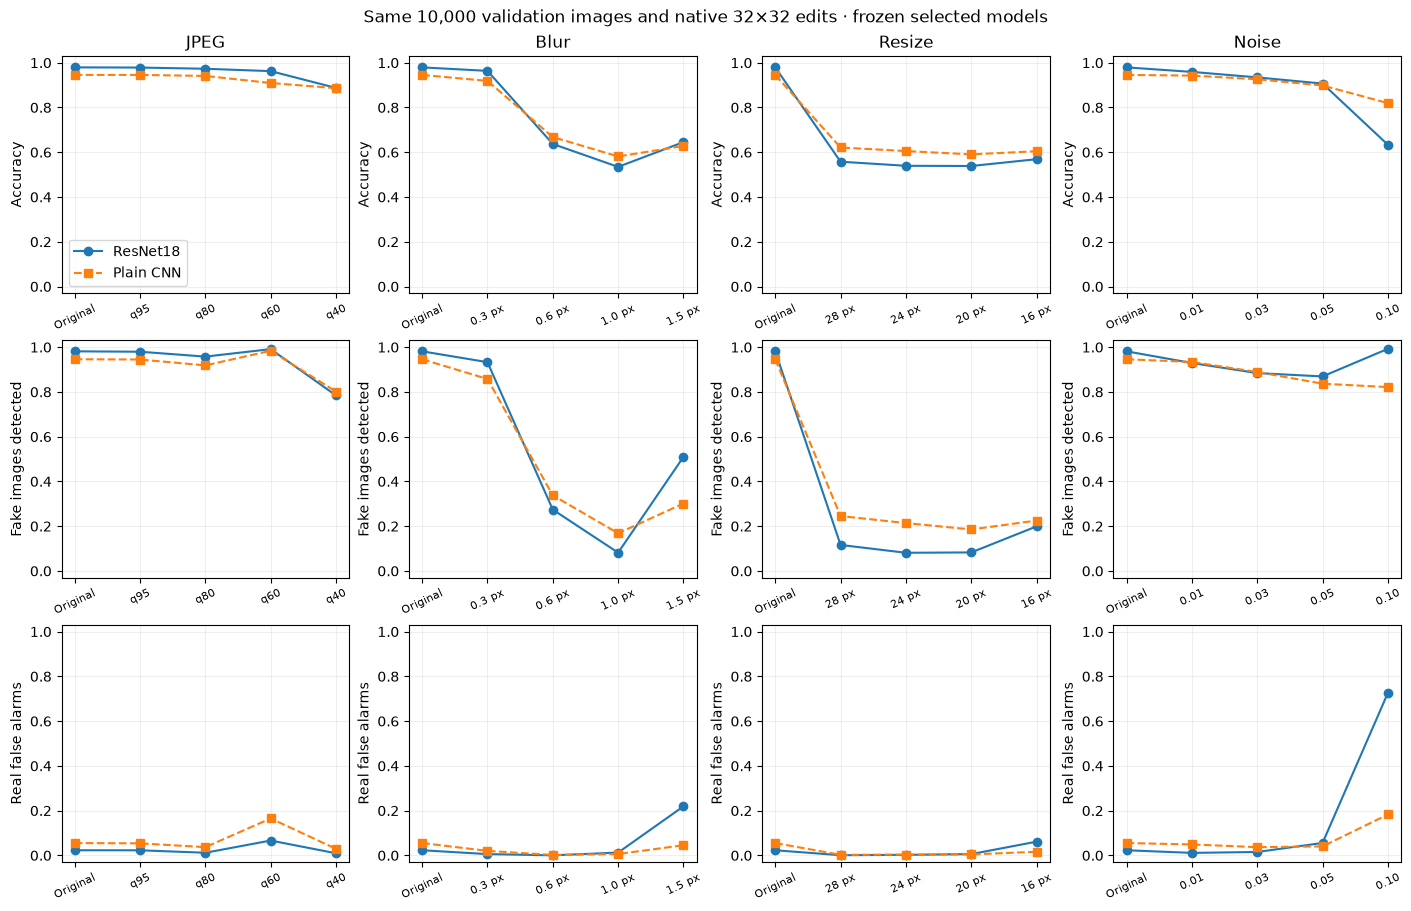

In [7]:
# Finish the figure after all panels have been drawn.
axes[0, 0].legend()
fig.suptitle("Same 10,000 validation images and native 32×32 edits · frozen selected models")
if SAVE_FIGURES:
    folder = ROOT / "results/phase1_comparison"
    folder.mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 5. What the modification tests show

Both models on the same validation images:

| Condition | Plain CNN accuracy | Fine-tuned ResNet18 accuracy |
| --- | ---: | ---: |
| Clean official test, 20,000 images | 94.290% | 97.735% |
| Original validation images | 94.54% | 97.92% |
| JPEG quality 60 | 90.94% | 96.24% |
| Gaussian blur, radius 0.6 | 66.79% | 63.69% |
| Resize 32 → 28 → 32 | 62.13% | 55.77% |
| Gaussian noise, standard deviation 0.05 | 89.83% | 90.68% |

Except for the explicitly marked official test row, these measurements use the same **10,000 validation images**, their original labels and the fixed 0.5 decision threshold.

The main finding is that better clean performance did not translate into consistently better performance after modification. ResNet18 retained more accuracy at JPEG quality 60 and noise standard deviation 0.05, but blur with radius 0.6 reduced accuracy to **63.69%**, and resizing 32 → 28 → 32 reduced it to **55.77%**. Both are below the corresponding CNN results. The resize failure is especially informative: the ResNet's fake-detection rate fell from **98.14% to 11.62%**, while only **0.08%** of resized real images were flagged as fake. At the fixed threshold it moved strongly toward predicting REAL, rather than making balanced errors in both directions. Its resize ROC-AUC remained about **0.916**, suggesting that some ranking information survived even though the fixed-threshold decisions deteriorated. This does not establish that adjusting the threshold would restore reliable performance across all conditions.

**Where Phase I continues.** `04_what_fools_the_detectors.ipynb` adds sharpening and colour edits and compares both models image by image. Sharpening is the mirror image of blur: 200 % sharpening makes ResNet18 flag 66.9 % of real photos, and sharpening blurred fakes again restores detection from 27.4 % to 90.6 %. The two models fail on largely the same blurred and resized images. Strong noise is where they differ most: at σ = 0.10 ResNet18 flags 72.6 % of real photos, the CNN 18.3 %.
